<a href="https://colab.research.google.com/github/asirabm/cctv-video-anomaly-detection/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **01 — Dataset Exploration and Data Quality Assessment**


Dataset source: Hugging Face — jinmang2/ucf_crime

*Install the required libraries*

In [1]:
!pip -q install -U huggingface_hub pandas matplotlib

In [2]:
%pip install --upgrade --force-reinstall pandas

  Using cached pandas-3.0.6-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached pandas-3.0.6-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (10.8 MB)
Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl (229 kB)
Using cached six-1.17.0-py2.py3-none-any.whl (11 kB)
  Attempting uninstall: six
    Found existing installation: six 1.17.0
    Uninstalling six-1.17.0:
      Successfully uninstalled six-1.17.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
  Attempting uninstall: python-dateut

# **Checking the Hugging Face dataset files**

In [3]:
from huggingface_hub import HfApi

rep_id = "jinmang2/ucf_crime"

api = HfApi()

file = api.list_repo_files(
    repo_id=rep_id,
    repo_type="dataset"
)

print("Dataset:", rep_id)
print("Number of files:", len(file))

for filename in file:
    print(filename)

Dataset: jinmang2/ucf_crime
Number of files: 24
.gitattributes
Anomaly-Videos-Part-1.zip
Anomaly-Videos-Part-2.zip
Anomaly-Videos-Part-3.zip
Anomaly-Videos-Part-4.zip
Normal_Videos_for_Event_Recognition.zip
README.md
Testing_Normal_Videos.zip
Training-Normal-Videos-Part-1.zip
Training-Normal-Videos-Part-2.zip
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/ClassIDs.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/test_001.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/test_002.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/test_003.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/test_004.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/train_001.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/train_002.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/train_003.txt
UCF_Crimes-Train-Test-Split/Action_Recognition_splits/train_004.txt
UCF_Crimes-Train-Test-Split/Anomaly_Detection_splits/Anomaly_Test.txt
UCF_Crimes-T

## **Download the official split files only**

In [4]:
from huggingface_hub import hf_hub_download
rep_id = "jinmang2/ucf_crime"

dir = (
    "UCF_Crimes-Train-Test-Split/"
    "Anomaly_Detection_splits/"
)

train_split_path = hf_hub_download(
    repo_id=rep_id,
    filename=dir + "Anomaly_Train.txt",
    repo_type="dataset"
)

test_split_path = hf_hub_download(
    repo_id=rep_id,
    filename=dir + "Anomaly_Test.txt",
    repo_type="dataset"
)

**Explore the split files**

In [5]:
import pandas as pd

with open(train_split_path, "r") as f_train:
    train_lines = [line.strip() for line in f_train if line.strip()]
train_lines[:10]
print(len(train_lines))

1610


In [6]:
with open(test_split_path, "r") as f_test:
    test_lines = [line.strip() for line in f_test if line.strip()]
test_lines[:10]

['Abuse/Abuse028_x264.mp4',
 'Abuse/Abuse030_x264.mp4',
 'Arrest/Arrest001_x264.mp4',
 'Arrest/Arrest007_x264.mp4',
 'Arrest/Arrest024_x264.mp4',
 'Arrest/Arrest030_x264.mp4',
 'Arrest/Arrest039_x264.mp4',
 'Arson/Arson007_x264.mp4',
 'Arson/Arson009_x264.mp4',
 'Arson/Arson010_x264.mp4']

In [7]:
print("Training entries:", len(train_lines))
print("Testing entries :", len(test_lines))

Training entries: 1610
Testing entries : 290


**Check split quality**

In [8]:
train_set=set(train_lines)
test_set=set(test_lines)
print("unique videos in train dataset: ",len(train_set))
print("unique videos in test dataset: ",len(test_set))

unique videos in train dataset:  1610
unique videos in test dataset:  290


In [9]:
overlap = train_set.intersection(test_set)

In [10]:
print("overlap entries: ", len(overlap))

overlap entries:  0


**Analyse Class Distribution in the Training and Testing Splits**

In [11]:
import re
import pandas as pd

In [12]:
def video_path_extractor(line):
  match=re.search(r'\S+\.mp4',line,flags=re.IGNORECASE)
  #print(match)
  if match:
    return match.group(0).replace('\\','/').lstrip('/')
  else:
    return None

#video_path_extractor('Anomaly-Videos-Part-1\\Abuse/Abuse001_x264.mp4')

In [13]:
def get_category(path):
  if not path:
    return None
  else:
    parts=path.split('/')
    if len(parts)>1:
      return parts[-2]
    filename=parts[-1]
    match_cat=re.match(r'^([A-Za-z]+)', filename)
    if match_cat:
      return match_cat.group(0)
    else:
      return None

In [14]:
get_category("Anomaly-Videos-Part-1/Abuse/Abuse001_x264.mp4")

'Abuse'

In [15]:
def identify_class(line):
    path = video_path_extractor(line)

    if not path:
        return "Unparsed"

    parts = path.split("/")
    category = parts[0].lower()

    if "normal" in category:
        return "Normal"

    return "Anomaly"

In [16]:
#test_lines

In [17]:
records = []
for split, entries in [('Train',train_lines),('Test',test_lines)]:
  for line in entries:
    path=video_path_extractor(line)
    class_name = identify_class(line)
    records.append(
        {
            "split":split,
            "raw_entry":line,
            "video_path":path,
            "category":get_category(path),
            "label": 1 if class_name == "Anomaly" else 0
        }
    )
  #print(records[:1000])


In [18]:
df=pd.DataFrame(records)

In [19]:
len(df)

1900

In [20]:
df.head(10)

,split,raw_entry,video_path,category,label
0,Train,Abuse/Abuse001_x264.mp4,Abuse/Abuse001_x264.mp4,Abuse,1
1,Train,Abuse/Abuse002_x264.mp4,Abuse/Abuse002_x264.mp4,Abuse,1
2,Train,Abuse/Abuse003_x264.mp4,Abuse/Abuse003_x264.mp4,Abuse,1
3,Train,Abuse/Abuse004_x264.mp4,Abuse/Abuse004_x264.mp4,Abuse,1
4,Train,Abuse/Abuse005_x264.mp4,Abuse/Abuse005_x264.mp4,Abuse,1
5,Train,Abuse/Abuse006_x264.mp4,Abuse/Abuse006_x264.mp4,Abuse,1
6,Train,Abuse/Abuse007_x264.mp4,Abuse/Abuse007_x264.mp4,Abuse,1
7,Train,Abuse/Abuse008_x264.mp4,Abuse/Abuse008_x264.mp4,Abuse,1
8,Train,Abuse/Abuse009_x264.mp4,Abuse/Abuse009_x264.mp4,Abuse,1
9,Train,Abuse/Abuse010_x264.mp4,Abuse/Abuse010_x264.mp4,Abuse,1


In [21]:
#test_df = df_anomaly[df_anomaly["category"] == "normal"]
#print(len(test_df))

In [22]:
print(df["category"].value_counts())

category
Training_Normal_Videos_Anomaly    800
RoadAccidents                     150
Robbery                           150
Testing_Normal_Videos_Anomaly     150
Burglary                          100
Stealing                          100
Abuse                              50
Arrest                             50
Arson                              50
Assault                            50
Explosion                          50
Fighting                           50
Shooting                           50
Shoplifting                        50
Vandalism                          50
Name: count, dtype: int64


In [23]:
df[df['label']==0]

,split,raw_entry,video_path,category,label
765,Train,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly,0
766,Train,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly,0
767,Train,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly,0
768,Train,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly,0
769,Train,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly/Normal_Videos00...,Training_Normal_Videos_Anomaly,0
...,...,...,...,...,...
1890,Test,Testing_Normal_Videos_Anomaly/Normal_Videos_93...,Testing_Normal_Videos_Anomaly/Normal_Videos_93...,Testing_Normal_Videos_Anomaly,0
1891,Test,Testing_Normal_Videos_Anomaly/Normal_Videos_94...,Testing_Normal_Videos_Anomaly/Normal_Videos_94...,Testing_Normal_Videos_Anomaly,0
1892,Test,Testing_Normal_Videos_Anomaly/Normal_Videos_94...,Testing_Normal_Videos_Anomaly/Normal_Videos_94...,Testing_Normal_Videos_Anomaly,0
1893,Test,Testing_Normal_Videos_Anomaly/Normal_Videos_94...,Testing_Normal_Videos_Anomaly/Normal_Videos_94...,Testing_Normal_Videos_Anomaly,0


In [24]:
df[df['label']==1]

,split,raw_entry,video_path,category,label
0,Train,Abuse/Abuse001_x264.mp4,Abuse/Abuse001_x264.mp4,Abuse,1
1,Train,Abuse/Abuse002_x264.mp4,Abuse/Abuse002_x264.mp4,Abuse,1
2,Train,Abuse/Abuse003_x264.mp4,Abuse/Abuse003_x264.mp4,Abuse,1
3,Train,Abuse/Abuse004_x264.mp4,Abuse/Abuse004_x264.mp4,Abuse,1
4,Train,Abuse/Abuse005_x264.mp4,Abuse/Abuse005_x264.mp4,Abuse,1
...,...,...,...,...,...
1895,Test,Vandalism/Vandalism007_x264.mp4,Vandalism/Vandalism007_x264.mp4,Vandalism,1
1896,Test,Vandalism/Vandalism015_x264.mp4,Vandalism/Vandalism015_x264.mp4,Vandalism,1
1897,Test,Vandalism/Vandalism017_x264.mp4,Vandalism/Vandalism017_x264.mp4,Vandalism,1
1898,Test,Vandalism/Vandalism028_x264.mp4,Vandalism/Vandalism028_x264.mp4,Vandalism,1


In [25]:
print("Total entries:", len(df))

print("Counts by split and class:")
print(pd.crosstab(df["split"],df["label"]))

print("Missing video paths:",df["video_path"].isna().sum())

print("Missing labels:",df["label"].isna().sum())

Total entries: 1900
Counts by split and class:
label    0    1
split          
Test   150  140
Train  800  810
Missing video paths: 0
Missing labels: 0


***Visualize Class Distrubution ***

In [26]:
dist_class=pd.crosstab(
    df['split'],
    df['label']
)

In [29]:
dist_class

label,0,1
split,,
Test,150,140
Train,800,810


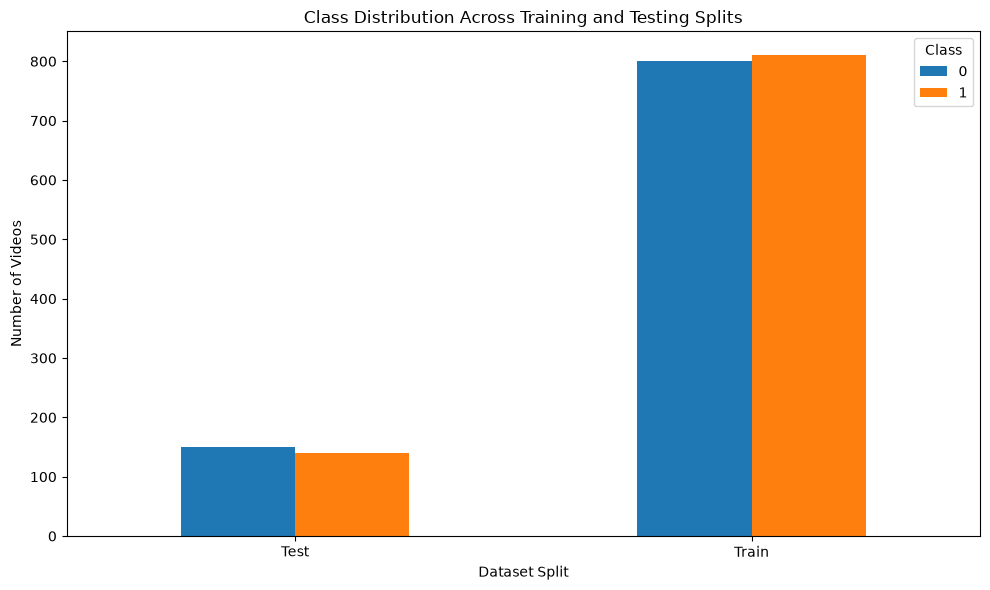

In [33]:
import matplotlib.pyplot as plot
dist_class.plot(kind="bar",figsize=(10,6))
plot.title("Class Distribution Across Training and Testing Splits")
plot.xlabel("Dataset Split")
plot.ylabel("Number of Videos")
plot.xticks(rotation=0)
plot.legend(title="Class")
plot.tight_layout()
plot.show()
